# Rb87 qubit states — magnetic sensitivity, magic fields, and collisional closedness

Companion to `structure_demo.ipynb`: use the sweep machinery to answer a
concrete question — *which pair of $5S_{1/2}$ sublevels makes a good qubit,
and at what magnetic field?*

Three criteria, in the order we check them:

1. **Magnetic-field sensitivity.** The qubit frequency is
   $\nu(B) = [E_b(B) - E_a(B)]/h$ and field noise dephases the qubit at a rate
   set by $d\nu/dB$. The best operating points are **magic fields** where
   $d\nu/dB = 0$ and only the curvature $d^2\nu/dB^2$ survives.
2. **Collisional closedness.** In a BEC (or any dense sample) the qubit states
   collide. A two-body **spin-exchange** collision conserves the total
   $m_{F,\mathrm{tot}} = m_{F,1} + m_{F,2}$; a pair channel is *closed* if no
   other channel with the same $m_{F,\mathrm{tot}}$ lies **lower in energy**
   at the operating field — there is then nowhere exothermic for the pair to
   go. We check all three combinations $aa$, $ab$, $bb$. (Dipolar relaxation
   can still change $m_{F,\mathrm{tot}}$; it is much weaker but not zero —
   see section 5.)
3. **Practicality.** $|\Delta m_F|$ is the number of photons needed to drive
   the transition (1 = a single microwave/RF photon, 2 = a two-photon
   microwave + RF drive), and the states should be readable out (section 7).

Contents: 1. setup — 2. Breit–Rabi — 3. sensitivity from a sweep — 4. the
clock pairs — 5. all magic points — 6. closedness — 7. readout — 8. the
clock pair in detail — 9. sensitivity and the field-noise budget —
10. preparing $|1,0\rangle$ — 11. summary — 12. further reading.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

from kamo import atom as make_atom
from kamo.hamiltonian import AtomicStructure

plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 100

## 1. Setup

One atom, one model (the ground manifold only — microwave/RF qubits live
entirely inside $5S_{1/2}$), one fine sweep reused for everything below.
`dB = 0.05 G` keeps the eigenstate tracking safe and gives smooth numerical
derivatives.

In [2]:
rb87 = make_atom("Rb87")
print(rb87, "  I =", rb87.I, "  gI =", rb87.gI)
print(rb87.hyperfine_constants(5, 0, 0.5))

model = AtomicStructure([(5, 0, 0.5)], atom=rb87)
res = model.magnetic_sweep(B_max=900.0, dB=0.05)
B = res.param

f_hfs = res.get_transition_frequency((5, 0, 0.5, 1, 0), (5, 0, 0.5, 2, 0), at=0.0)
print(f"hyperfine splitting: {f_hfs/1e9:.9f} GHz   (Steck: 6.834682611 GHz)")

Rubidium87(use_portal=True, portal_species='Rb1')   I = 1.5   gI = -0.0009951414
5s1/2: A = 3417.34131 MHz [portal (measured)], B = 0 MHz [exact (J = 1/2)]


hyperfine splitting: 6.834682614 GHz   (Steck: 6.834682611 GHz)


## 2. The Breit–Rabi diagram

$I = 3/2$, so $F = 1, 2$ with $g_F \simeq \mp 1/2$: at low field the two
manifolds fan out symmetrically at $\mp 0.70$ MHz/G per unit $m_F$; the
Paschen–Back regime sets in on the scale of
$A_{\mathrm{hfs}}/\mu_B \sim 2.4$ kG. Everything interesting for qubits
happens on the left half of this plot.

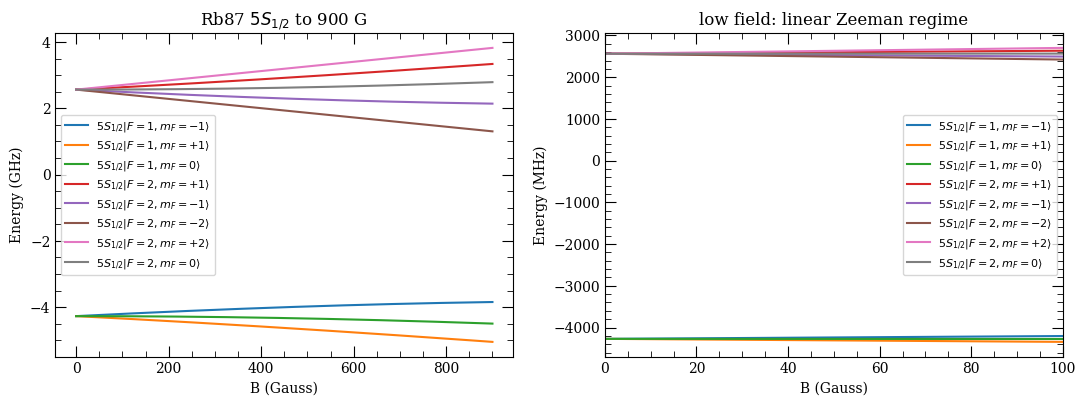

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
res.plot(ax=ax[0], states=(5, 0, 0.5), coupled_labels=True, energy_unit="GHz")
ax[0].set_title("Rb87 $5S_{1/2}$ to 900 G")
res.plot(ax=ax[1], states=(5, 0, 0.5), coupled_labels=True, xlim=(0, 100))
ax[1].set_title("low field: linear Zeeman regime");

## 3. Sensitivity, computed from the sweep tracks

We take the **whole tracked transition frequency** $f(B)$ from the sweep and
differentiate it numerically with `np.gradient`. (This is more robust than
calling `atom.get_transition_sensitivity` at isolated fields: that method
finite-differences an interpolated sweep, and with its default grid the
difference step can be smaller than the grid spacing.) The same helper finds
**magic fields** as the zero crossings of $d\nu/dB$, refined by linear
interpolation, and reports the curvature there.

In [4]:
G = (5, 0, 0.5)   # the ground manifold (n, l, j)

def track(s1, s2):
    '''Signed transition frequency f(B) = E2 - E1 in Hz on the sweep grid.'''
    return res.get_transition_frequency(G + s1, G + s2)

def sensitivity(s1, s2):
    '''d f / dB in Hz/G on the sweep grid.'''
    return np.gradient(track(s1, s2), B)

def magic_points(s1, s2, B_min=0.5):
    '''(B0, f(B0), d2f/dB2) for every zero of df/dB above B_min.'''
    f, sens = track(s1, s2), sensitivity(s1, s2)
    curv = np.gradient(sens, B)
    i0 = np.searchsorted(B, B_min)
    out = []
    for i in np.where(np.diff(np.sign(sens[i0:])) != 0)[0] + i0:
        b0 = B[i] - sens[i] * (B[i + 1] - B[i]) / (sens[i + 1] - sens[i])
        out.append((b0, abs(f[i]), curv[i]))
    return out

# sanity check against the well-known magic point of |1,-1> <-> |2,+1>
for b0, f0, c in magic_points((1, -1), (2, 1)):
    print(f"|1,-1> <-> |2,+1>: magic at B = {b0:.3f} G, f = {f0/1e9:.9f} GHz, "
          f"d2f/dB2 = {c:.1f} Hz/G^2   (literature: 3.229 G, 2*431.36 Hz/G^2)")

|1,-1> <-> |2,+1>: magic at B = 3.229 G, f = 6.834678117 GHz, d2f/dB2 = 862.7 Hz/G^2   (literature: 3.229 G, 2*431.36 Hz/G^2)


## 4. The two textbook pairs

**$|1,0\rangle \leftrightarrow |2,0\rangle$** — the hyperfine clock
transition. Both states have $m_F = 0$, so the linear Zeeman shift vanishes at
$B = 0$ and the transition is purely quadratic,
$\delta\nu = 575.15\ \mathrm{Hz/G^2}\, B^2$. Its only magic field is $B = 0$
— which you cannot operate at (no quantization axis) — so at any working
field it has a *residual* linear sensitivity $2 \times 575\ \mathrm{Hz/G^2} \times B$.

**$|1,-1\rangle \leftrightarrow |2,+1\rangle$** — the two-photon magic pair.
The linear Zeeman shifts of the two states nearly cancel
($g_F$ flips sign between the manifolds while $m_F$ flips sign too), and the
small nuclear term plus the quadratic shift move the extremum of $\nu(B)$ out
to a finite field: $d\nu/dB = 0$ at **3.229 G**, where
$\delta\nu \simeq 431\ \mathrm{Hz/G^2} \, (B - B_0)^2$. This is the pair used
for second-scale coherence in Rb87 condensate interferometry.

at the 3.229 G magic point, 1 mG excursions shift the qubit by 4.31e-01 mHz;
the clock pair at 3.229 G would shift by 3.714 Hz per mG (linear).


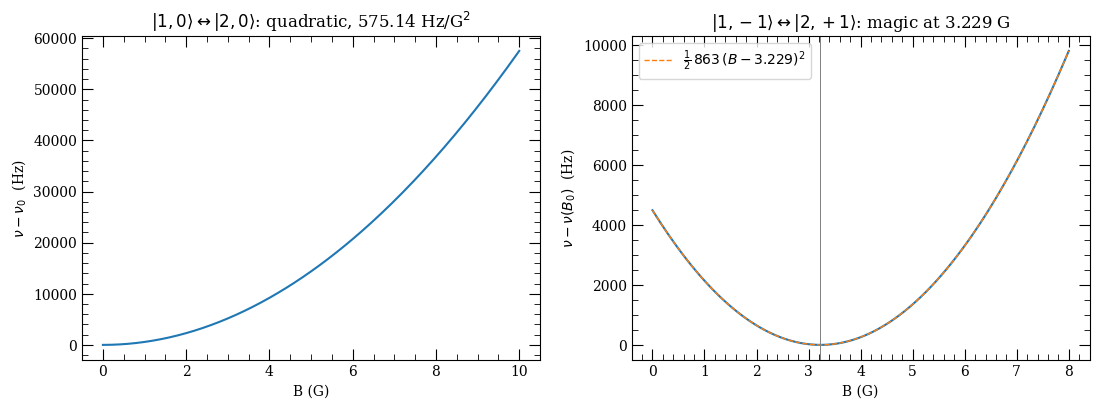

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

# clock transition: quadratic shift from 0
m = B <= 10.0
f_clock = np.abs(track((1, 0), (2, 0)))
ax[0].plot(B[m], f_clock[m] - f_clock[0])
coef = np.polyfit(B[m], f_clock[m] - f_clock[0], 2)[0]
ax[0].set_xlabel("B (G)"); ax[0].set_ylabel(r"$\nu - \nu_0$  (Hz)")
ax[0].set_title(rf"$|1,0\rangle \leftrightarrow |2,0\rangle$: quadratic, {coef:.2f} Hz/G$^2$")

# magic pair: parabola around 3.229 G
m = B <= 8.0
f_m = np.abs(track((1, -1), (2, 1)))
(b0, f0, c), = magic_points((1, -1), (2, 1))
ax[1].plot(B[m], f_m[m] - f0)
ax[1].plot(B[m], 0.5 * c * (B[m] - b0)**2, "--", lw=1, label=rf"$\frac{{1}}{{2}}\,{c:.0f}\,(B-{b0:.3f})^2$")
ax[1].axvline(b0, color="gray", lw=0.7)
ax[1].set_xlabel("B (G)"); ax[1].set_ylabel(r"$\nu - \nu(B_0)$  (Hz)")
ax[1].set_title(rf"$|1,-1\rangle \leftrightarrow |2,+1\rangle$: magic at {b0:.3f} G")
ax[1].legend();

dB_noise = 1e-3   # 1 mG of field noise
print(f"at the 3.229 G magic point, 1 mG excursions shift the qubit by "
      f"{0.5 * c * dB_noise**2 * 1e3:.2e} mHz;")
print(f"the clock pair at 3.229 G would shift by "
      f"{2 * coef * b0 * dB_noise:.3f} Hz per mG (linear).")

## 5. Every magic point in the ground manifold

Scan **all pairs** of the eight sublevels for zero crossings of $d\nu/dB$
between 0.5 and 900 G. Beyond the 3.229 G point, Rb87 has a second family of
magic fields near 650 G, in the intermediate (Breit–Rabi) regime — and these
are **single-photon** ($|\Delta m_F| = 1$) microwave transitions, which is
experimentally much lighter than the two-photon drive of the 3.229 G pair.

In [6]:
states = [(1, -1), (1, 0), (1, 1), (2, -2), (2, -1), (2, 0), (2, 1), (2, 2)]

rows = []
for s1, s2 in itertools.combinations(states, 2):
    for b0, f0, c in magic_points(s1, s2):
        rows.append((s1, s2, abs(s2[1] - s1[1]), b0, f0, c))

print(f"{'pair':<24}{'|dmF|':>6}{'B_magic (G)':>13}{'f (GHz)':>15}{'d2f/dB2 (Hz/G^2)':>19}")
for s1, s2, dmF, b0, f0, c in sorted(rows, key=lambda r: r[3]):
    print(f"|{s1[0]},{s1[1]:+d}> <-> |{s2[0]},{s2[1]:+d}>   {dmF:>5}{b0:>13.3f}{f0/1e9:>15.9f}{c:>19.1f}")

pair                     |dmF|  B_magic (G)        f (GHz)   d2f/dB2 (Hz/G^2)
|1,-1> <-> |2,+1>       2        3.229    6.834678117              862.7
|1,+0> <-> |2,-1>       1      651.895    6.602705296             1116.8
|1,-1> <-> |2,+0>       1      654.389    6.600885872             1116.9


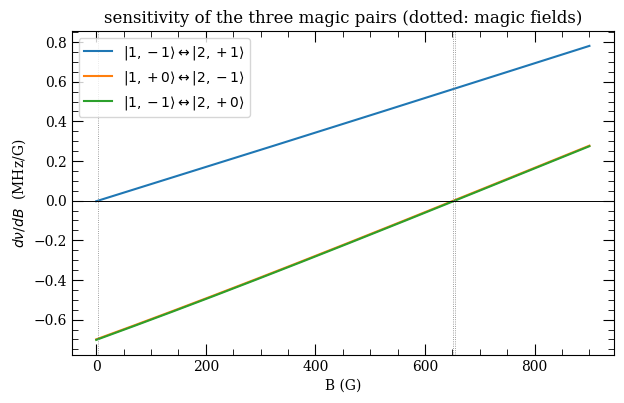

In [7]:
fig, ax = plt.subplots()
for s1, s2 in [((1, -1), (2, 1)), ((1, 0), (2, -1)), ((1, -1), (2, 0))]:
    sens = sensitivity(s1, s2)
    ax.plot(B, sens / 1e6, label=rf"$|{s1[0]},{s1[1]:+d}\rangle \leftrightarrow |{s2[0]},{s2[1]:+d}\rangle$")
ax.axhline(0, color="k", lw=0.7)
for _, _, _, b0, _, _ in rows:
    ax.axvline(b0, color="gray", lw=0.6, ls=":")
ax.set_xlabel("B (G)"); ax.set_ylabel(r"$d\nu/dB$  (MHz/G)")
ax.set_title("sensitivity of the three magic pairs (dotted: magic fields)")
ax.legend();

## 6. Collisional closedness

`closed_report(pair, B)` enumerates every two-body channel of ground
sublevels with the same total $m_F$ and lists the ones **below** the incoming
pair — the exothermic spin-exchange exits. An empty list means the pair is
energetically closed at that field.

Two general rules emerge (both visible in the output):

* **Both atoms in the lower manifold ($F = 1$) ⇒ closed.** There is nothing
  below to fall to, and within the manifold the Breit–Rabi quadratic shift
  makes the energy *convex* in $m_F$, so "spreading" collisions
  $(m_F, m_F) \to (m_F{-}1, m_F{+}1)$ cost energy.
* **Any atom in $F = 2$ ⇒ energetically open** (exits releasing up to the
  6.8 GHz hyperfine energy)... except the doubly-stretched
  $|2,+2\rangle{+}|2,+2\rangle$ channel, whose $m_{F,\mathrm{tot}} = +4$
  cannot be reached by any lower pair.

Rb87 gets away with $F=2$ qubit states anyway: its singlet and triplet
scattering lengths are nearly equal ($a_s = 90.4\,a_0$, $a_t = 98.98\,a_0$),
and s-wave spin-exchange amplitudes scale with $a_t - a_s$, so the
energetically-open exits of the 3.229 G pair are *dynamically* suppressed —
measured lifetimes of $|1,-1\rangle{+}|2,+1\rangle$ mixtures reach seconds.
This is a fortunate coincidence of Rb87, **not** a property you can assume
for other species (Rb85 has $a_s \neq a_t$ wildly — see the Rb85 notebook).

In [8]:
def closed_report(pair, B0, tol_hz=100.0):
    '''Exothermic spin-exchange exit channels for a two-body pair at B0 (G).

    pair: ((F, mF), (F, mF)).  Returns a list of (chan1, chan2, dE_MHz).
    '''
    all_states = model.states()
    lab = {s: res.convert_label(s)[3:] for s in all_states}
    E = {lab[s]: res.get_energy(*s, at=B0) for s in all_states}
    a, b = pair
    E_in, mF_tot = E[a] + E[b], a[1] + b[1]
    out = []
    for x in E:
        for y in E:
            if x <= y and x[1] + y[1] == mF_tot and {x, y} != {a, b}:
                dE = E[x] + E[y] - E_in
                if dE < -tol_hz:
                    out.append((x, y, dE / 1e6))
    return sorted(out, key=lambda r: r[2])

qubit_pairs = [((1, -1), (2, 1)), ((1, 0), (2, -1)), ((1, -1), (2, 0)),
               ((1, 0), (2, 0)), ((1, -1), (1, 0)), ((2, 2), (2, 2))]
for (a, b) in qubit_pairs:
    print(f"qubit |{a[0]},{a[1]:+d}> & |{b[0]},{b[1]:+d}>  at 3.23 G:")
    for combo in dict.fromkeys([(a, a), (a, b), (b, b)]):
        ex = closed_report(combo, 3.23)
        s = "closed" if not ex else (f"OPEN: " + ", ".join(
            f"|{x[0]},{x[1]:+d}>+|{y[0]},{y[1]:+d}> ({d:+.0f} MHz)" for x, y, d in ex[:3])
            + (" ..." if len(ex) > 3 else ""))
        print(f"   {combo[0]}+{combo[1]}: {s}")
    print()

qubit |1,-1> & |2,+1>  at 3.23 G:
   (1, -1)+(1, -1): closed
   (1, -1)+(2, 1): OPEN: |1,+0>+|1,+0> (-6839 MHz), |1,-1>+|1,+1> (-6839 MHz), |1,+1>+|2,-1> (-9 MHz) ...
   (2, 1)+(2, 1): OPEN: |1,+1>+|1,+1> (-13678 MHz), |1,+1>+|2,+1> (-6839 MHz), |1,+0>+|2,+2> (-6835 MHz) ...

qubit |1,+0> & |2,-1>  at 3.23 G:
   (1, 0)+(1, 0): closed
   (1, 0)+(2, -1): OPEN: |1,-1>+|1,+0> (-6830 MHz), |1,+1>+|2,-2> (-5 MHz)
   (2, -1)+(2, -1): OPEN: |1,-1>+|1,-1> (-13660 MHz), |1,+0>+|2,-2> (-6835 MHz), |1,-1>+|2,-1> (-6830 MHz) ...

qubit |1,-1> & |2,+0>  at 3.23 G:
   (1, -1)+(1, -1): closed
   (1, -1)+(2, 0): OPEN: |1,-1>+|1,+0> (-6835 MHz), |1,+1>+|2,-2> (-9 MHz), |1,+0>+|2,-1> (-5 MHz)
   (2, 0)+(2, 0): OPEN: |1,+0>+|1,+0> (-13669 MHz), |1,-1>+|1,+1> (-13669 MHz), |1,+1>+|2,-1> (-6839 MHz) ...

qubit |1,+0> & |2,+0>  at 3.23 G:
   (1, 0)+(1, 0): closed
   (1, 0)+(2, 0): OPEN: |1,+0>+|1,+0> (-6835 MHz), |1,-1>+|1,+1> (-6835 MHz), |1,+1>+|2,-1> (-5 MHz)
   (2, 0)+(2, 0): OPEN: |1,+0>+|1,+0> (-13669 

### Sensitivity at your working field

The same numbers as a table — pick a field, read off $d\nu/dB$ and what 1 mG
of field noise does to each candidate pair.

In [9]:
fields = [1.0, 3.229, 10.0, 100.0, 500.0, 651.9]
pairs = [((1, 0), (2, 0)), ((1, -1), (2, 1)), ((1, 0), (2, -1)),
         ((1, -1), (2, 0)), ((1, -1), (1, 0))]

hdr = "pair".ljust(22) + "".join(f"{b:>12.1f} G" for b in fields)
print(hdr); print("-" * len(hdr))
for s1, s2 in pairs:
    sens = sensitivity(s1, s2)
    vals = np.interp(fields, B, sens)
    print(f"|{s1[0]},{s1[1]:+d}> <-> |{s2[0]},{s2[1]:+d}>".ljust(22)
          + "".join(f"{v/1e3:>11.2f} " for v in vals) + "  kHz/G")
print()
print("1 mG of field noise dephases at df = sens * 1e-3 G, e.g. "
      f"{np.interp(100.0, B, sensitivity((1, -1), (1, 0))) * 1e-3:.1f} Hz "
      "for |1,-1> <-> |1,0> at 100 G.")

pair                           1.0 G         3.2 G        10.0 G       100.0 G       500.0 G       651.9 G
----------------------------------------------------------------------------------------------------------
|1,+0> <-> |2,+0>            1.15        3.71       11.50      114.93      563.42      724.42   kHz/G
|1,-1> <-> |2,+1>           -1.92        0.00        5.84       83.50      430.51      563.43   kHz/G
|1,+0> <-> |2,-1>         -698.58     -696.33     -689.51     -597.65     -168.78        0.01   kHz/G
|1,-1> <-> |2,+0>         -701.36     -699.12     -692.29     -600.43     -171.57       -2.78   kHz/G
|1,-1> <-> |1,+0>         -702.51     -702.83     -703.79     -715.36     -734.98     -727.20   kHz/G

1 mG of field noise dephases at df = sens * 1e-3 G, e.g. -715.4 Hz for |1,-1> <-> |1,0> at 100 G.


## 7. Readout

State-selective detection wants a **closed optical cycling transition**. For
Rb87 that is the stretched D2 line
$|F{=}2, m_F{=}\pm2\rangle \to |F'{=}3, m_{F'}{=}\pm3\rangle$ ($\sigma^\pm$):
the excited state can only decay back to the stretched ground state. None of
the magic-pair states is stretched, so readout means mapping the qubit onto
the stretched state (microwave pulses) or blowing away one qubit state and
imaging the rest — standard, but it belongs in the plan.

In [10]:
(g_nljF, e_nljF) = rb87.cycling_transition
print("stretched D2 cycling transition:", g_nljF, "->", e_nljF)
print("i.e. 5S1/2 F=2 -> 5P3/2 F'=3, drive sigma+/- on mF = +/-2 -> mF' = +/-3")

stretched D2 cycling transition: (5, 0, 0.5, 2.0) -> (5, 1, 1.5, 3.0)
i.e. 5S1/2 F=2 -> 5P3/2 F'=3, drive sigma+/- on mF = +/-2 -> mF' = +/-3


## 8. The clock pair in detail: state energies and splitting

The two clock states are the only $m_F = 0$ sublevels, and they **repel each
other** through the transverse Zeeman coupling: at low field
$E_{|2,0\rangle}$ rises and $E_{|1,0\rangle}$ falls, each quadratically at
$\pm 287.6\ \mathrm{Hz/G^2}$ (their difference is the clock shift,
$575.15\ \mathrm{Hz/G^2}$). At high field they connect adiabatically to
$|m_J = +1/2, m_I = -1/2\rangle$ and $|m_J = -1/2, m_I = +1/2\rangle$ and
run apart at the full electronic slope, $\approx 2.8$ MHz/G — the clock
character is a *low-field* property.

quadratic coefficient of |2,0>: +287.56 Hz/G^2
quadratic coefficient of |1,0>: -287.56 Hz/G^2


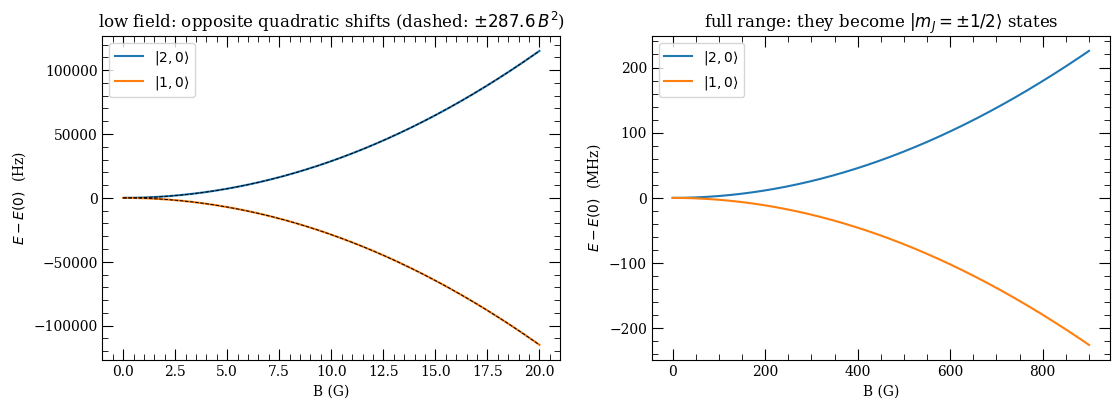

In [11]:
E1 = res.get_energy(5, 0, 0.5, 1, 0)     # full tracks vs B
E2 = res.get_energy(5, 0, 0.5, 2, 0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
m = B <= 20.0
ax[0].plot(B[m], (E2[m] - E2[0]), label=r"$|2,0\rangle$")
ax[0].plot(B[m], (E1[m] - E1[0]), label=r"$|1,0\rangle$")
for E, sgn in [(E2, +1), (E1, -1)]:
    c = np.polyfit(B[m], E[m] - E[0], 2)[0]
    ax[0].plot(B[m], c * B[m]**2, "k--", lw=0.7)
ax[0].set_xlabel("B (G)"); ax[0].set_ylabel(r"$E - E(0)$  (Hz)")
ax[0].set_title("low field: opposite quadratic shifts (dashed: $\\pm 287.6\\,B^2$)")
ax[0].legend()

ax[1].plot(B, (E2 - E2[0]) / 1e6, label=r"$|2,0\rangle$")
ax[1].plot(B, (E1 - E1[0]) / 1e6, label=r"$|1,0\rangle$")
ax[1].set_xlabel("B (G)"); ax[1].set_ylabel(r"$E - E(0)$  (MHz)")
ax[1].set_title(r"full range: they become $|m_J = \pm 1/2\rangle$ states")
ax[1].legend();

for name, E in [("|2,0>", E2), ("|1,0>", E1)]:
    c = np.polyfit(B[m], E[m] - E[0], 2)[0]
    print(f"quadratic coefficient of {name}: {c:+.2f} Hz/G^2")

The **splitting** itself — the qubit frequency your microwave source must
follow. Left: the low-field clock regime, where the shift is the textbook
$575.15\,B^2$ (at 1 G the qubit sits 575 Hz above the zero-field hyperfine
splitting; at 10 G, 57.5 kHz). Right: the full sweep — by 900 G the
"clock" transition has moved 1.9 GHz and is a clock in name only.

B =    0.5 G: clock shift =          143.8 Hz   (nu = 6.834682758 GHz)
B =    1.0 G: clock shift =          575.1 Hz   (nu = 6.834683189 GHz)
B =    2.0 G: clock shift =         2300.6 Hz   (nu = 6.834684915 GHz)
B =    5.0 G: clock shift =        14378.6 Hz   (nu = 6.834696993 GHz)
B =   10.0 G: clock shift =        57514.4 Hz   (nu = 6.834740128 GHz)
B =  100.0 G: clock shift =      5749041.9 Hz   (nu = 6.840431656 GHz)


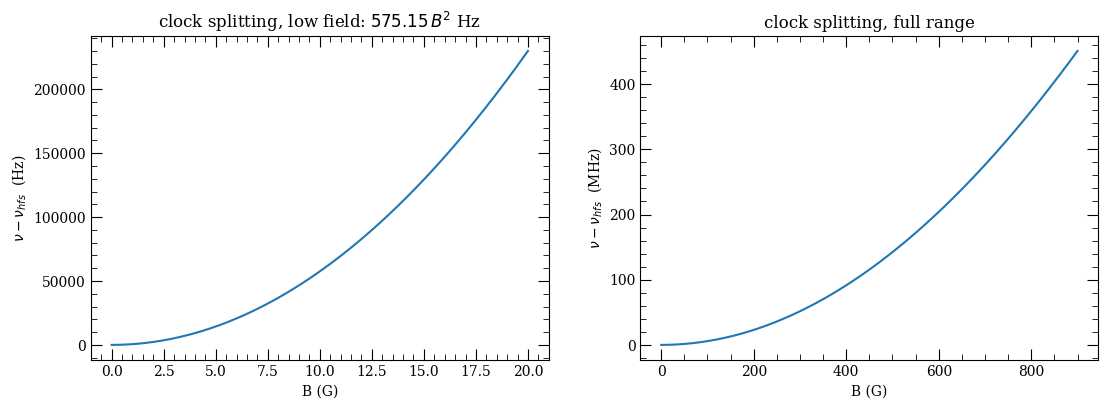

In [12]:
f_clock = np.abs(track((1, 0), (2, 0)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
m = B <= 20.0
ax[0].plot(B[m], f_clock[m] - f_clock[0])
ax[0].set_xlabel("B (G)"); ax[0].set_ylabel(r"$\nu - \nu_{hfs}$  (Hz)")
ax[0].set_title(r"clock splitting, low field: $575.15\,B^2$ Hz")
ax[1].plot(B, (f_clock - f_clock[0]) / 1e6)
ax[1].set_xlabel("B (G)"); ax[1].set_ylabel(r"$\nu - \nu_{hfs}$  (MHz)")
ax[1].set_title("clock splitting, full range");

for Bq in [0.5, 1.0, 2.0, 5.0, 10.0, 100.0]:
    df = np.interp(Bq, B, f_clock) - f_clock[0]
    print(f"B = {Bq:6.1f} G: clock shift = {df:14.1f} Hz   (nu = {np.interp(Bq, B, f_clock)/1e9:.9f} GHz)")

## 9. Sensitivity vs field, and the field-noise budget

Since the clock shift is quadratic, the sensitivity is **linear in the
operating field**: $d\nu/dB = 1150.3\ \mathrm{Hz/G^2} \times B$. You choose
your own sensitivity by choosing the bias field — the only reason not to run
arbitrarily low is that you need a quantization axis and (section 10)
protection against spin-mixing collisions. The table converts to the
practical question: *what does my field noise cost in qubit frequency?* For
a target inhomogeneous linewidth $\delta\nu$ and field noise $\delta B$,
you need $B < \delta\nu / (1150\,\delta B)$.

   B (G)   dnu/dB (Hz/G)   per mG (Hz)  per 100 uG (Hz)
     0.1           115.0         0.115           0.0115
     0.3           345.1         0.345           0.0345
     0.5           575.1         0.575           0.0575
     1.0          1150.3         1.150           0.1150
     2.0          2300.6         2.301           0.2301
     5.0          5751.4         5.751           0.5751
    10.0         11502.8        11.503           1.1503

e.g. for a 1 Hz inhomogeneous linewidth with 1 mG field noise, stay below B = 0.87 G


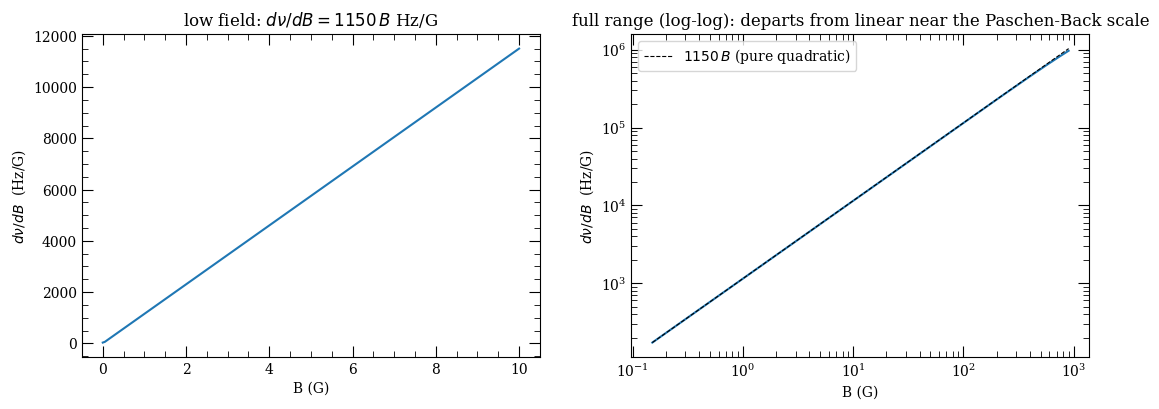

In [13]:
sens_clock = sensitivity((1, 0), (2, 0))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
m = B <= 10.0
ax[0].plot(B[m], sens_clock[m])
ax[0].set_xlabel("B (G)"); ax[0].set_ylabel(r"$d\nu/dB$  (Hz/G)")
ax[0].set_title(r"low field: $d\nu/dB = 1150\,B$ Hz/G")
mask = B > 0.1
ax[1].loglog(B[mask], sens_clock[mask])
ax[1].loglog(B[mask], 1150.3 * B[mask], "k--", lw=0.8, label=r"$1150\,B$ (pure quadratic)")
ax[1].set_xlabel("B (G)"); ax[1].set_ylabel(r"$d\nu/dB$  (Hz/G)")
ax[1].set_title("full range (log-log): departs from linear near the Paschen-Back scale")
ax[1].legend();

print(f"{'B (G)':>8}{'dnu/dB (Hz/G)':>16}{'per mG (Hz)':>14}{'per 100 uG (Hz)':>17}")
for Bq in [0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]:
    s = np.interp(Bq, B, sens_clock)
    print(f"{Bq:>8.1f}{s:>16.1f}{s*1e-3:>14.3f}{s*1e-4:>17.4f}")
print()
print("e.g. for a 1 Hz inhomogeneous linewidth with 1 mG field noise, stay below "
      f"B = {1.0/(1150.3*1e-3):.2f} G")

## 10. Getting into $|1,0\rangle$

$|1,0\rangle$ has no linear Zeeman shift, and its quadratic shift is *down*
(high-field-seeking): **a magnetic trap cannot hold it**, so "evaporate in a
magnetic trap directly into $|1,0\rangle$" is out. Both standard routes go
through an optical dipole trap, and both are routine:

**(A) All-optical: evaporate the $F{=}1$ mixture and distill.** Optically
pump to $F = 1$, load the dipole trap, and evaporate with a magnetic
gradient applied. The gradient tilts the trap for $m_F = \pm 1$
($\mp 0.70$ MHz/G per G/cm of gradient) but not for $m_F = 0$, so the
$\pm 1$ components spill during forced evaporation and the condensate forms
directly in $|1,0\rangle$ (standard practice in spinor-BEC labs). Purity is
set by how early the gradient is applied.

**(B) Evaporate in $|1,-1\rangle$, transfer after the BEC is made.** Two
microwave π-pulses: $|1,-1\rangle \to |2,0\rangle$ ($\sigma^+$, sits
$0.70\ \mathrm{MHz/G} \times B$ *below* the clock line — trivially resolved
at any sensible field), then the clock pulse $|2,0\rangle \to |1,0\rangle$.
Leftover $|1,-1\rangle$ atoms are removed with a short gradient spill
(again, $m_F = 0$ is immune) and leftover $F = 2$ atoms with a resonant
blow-away pulse. Transfer fidelity is a microwave-calibration problem, not a
thermodynamic one — heating is negligible.

An RF-only transfer *within* $F = 1$ is harder than it looks: the two rungs
$|1,-1\rangle \to |1,0\rangle$ and $|1,0\rangle \to |1,+1\rangle$ differ
only by the quadratic Zeeman splitting $2q$, so a π-pulse on one rung needs
a Rabi frequency well below $2q$ — the cell below shows what field that
requires. Route (B)'s microwave detour avoids the issue entirely.

**Why a bias field of $\sim$0.5–2 G is the sweet spot.** The spin-mixing
collision $2\,|1,0\rangle \to |1,+1\rangle + |1,-1\rangle$ conserves $m_F$
and is endothermic by exactly $2q$ ($q \simeq 71.9\ \mathrm{Hz/G^2}\,B^2$).
Rb87's $F{=}1$ spin-dependent interaction is tiny
($|c_2|\,n \sim h \times$ a few Hz at BEC densities), so once
$q \gg |c_2| n$ — i.e. $B \gtrsim 0.5$ G — the $|1,0\rangle$ condensate is
protected against spin mixing. Combined with section 9, that puts the
operating point at 0.5–2 G: spin-mixing safe, quantization axis defined,
and clock sensitivity still only 0.6–2.3 Hz/mG.

**Readout.** A dispersive probe parked between the $F{=}1$ and $F{=}2$ D2
lines (\~3.4 GHz from each) picks up opposite-sign phase shifts from the
two clock states, so phase-contrast imaging measures the population
difference directly — and both states being $m_F = 0$, there is no
first-order Zeeman pulling of the probe detuning either.

  B (G)      q (Hz)     2q (Hz)   RF pi-pulse must be slower than ~1/(2q)
    0.5        18.0        35.9   (    27.8 ms)
    1.0        71.9       143.8   (     7.0 ms)
    2.0       287.6       575.1   (     1.7 ms)
    5.0      1797.3      3594.6   (     0.3 ms)
   10.0      7189.2     14378.4   (     0.1 ms)


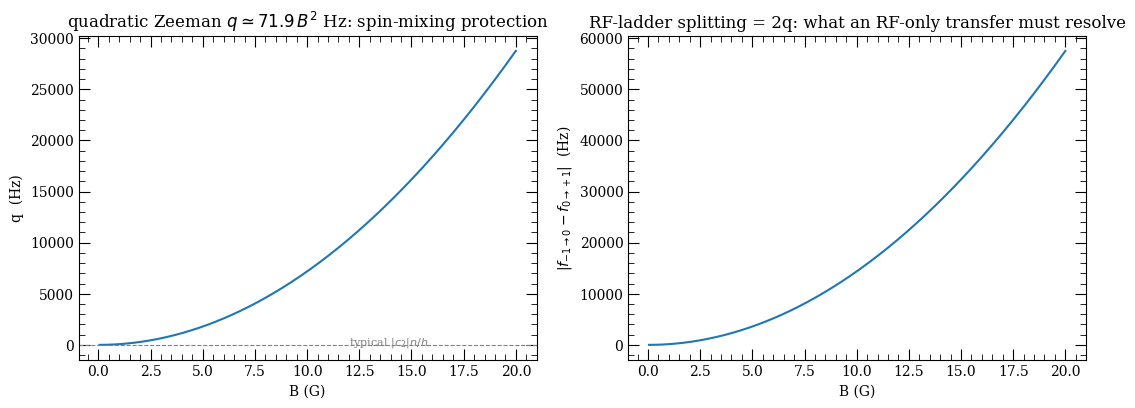

In [14]:
# quadratic Zeeman parameter q and the RF-ladder resolution 2q
E1m = res.get_energy(5, 0, 0.5, 1, -1)
E1p = res.get_energy(5, 0, 0.5, 1, 1)
q = (E1p + E1m - 2 * E1) / 2.0          # spin-mixing energy per pair / 2

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
m = (B > 0) & (B <= 20.0)
ax[0].plot(B[m], q[m])
ax[0].set_xlabel("B (G)"); ax[0].set_ylabel("q  (Hz)")
ax[0].set_title(r"quadratic Zeeman $q \simeq 71.9\,B^2$ Hz: spin-mixing protection")
ax[0].axhline(10, color="gray", lw=0.8, ls="--")
ax[0].annotate(r"typical $|c_2|n/h$", (12, 12), fontsize=8, color="gray")

f_rf1 = np.abs(track((1, -1), (1, 0)))   # the two RF rungs of F=1
f_rf2 = np.abs(track((1, 0), (1, 1)))
ax[1].plot(B[m], np.abs(f_rf1 - f_rf2)[m])
ax[1].set_xlabel("B (G)"); ax[1].set_ylabel(r"$|f_{-1\to 0} - f_{0\to +1}|$  (Hz)")
ax[1].set_title("RF-ladder splitting = 2q: what an RF-only transfer must resolve");

print(f"{'B (G)':>7}{'q (Hz)':>12}{'2q (Hz)':>12}   RF pi-pulse must be slower than ~1/(2q)")
for Bq in [0.5, 1.0, 2.0, 5.0, 10.0]:
    qq = np.interp(Bq, B, q)
    print(f"{Bq:>7.1f}{qq:>12.1f}{2*qq:>12.1f}   ({1/(2*qq)*1e3:8.1f} ms)")

In [15]:
# the microwave transfer route (B) at a 2 G bias field
B_prep = 2.0
f_A = np.interp(B_prep, B, np.abs(track((1, -1), (2, 0))))   # pulse 1: |1,-1> -> |2,0>
f_B = np.interp(B_prep, B, np.abs(track((1, 0), (2, 0))))    # pulse 2: clock
print(f"at B = {B_prep} G:")
print(f"   pulse 1  |1,-1> -> |2,0>  (sigma+): {f_A/1e9:.9f} GHz")
print(f"   pulse 2  |2,0>  -> |1,0>  (pi):     {f_B/1e9:.9f} GHz")
print(f"   separation from the clock line: {(f_B - f_A)/1e6:.3f} MHz -> trivially resolved")
print(f"   then: gradient spill removes leftover |1,-1> (m_F = 0 unaffected),")
print(f"         resonant F=2 light removes any leftover |2,0>")

at B = 2.0 G:
   pulse 1  |1,-1> -> |2,0>  (sigma+): 6.833279889 GHz
   pulse 2  |2,0>  -> |1,0>  (pi):     6.834684915 GHz
   separation from the clock line: 1.405 MHz -> trivially resolved
   then: gradient spill removes leftover |1,-1> (m_F = 0 unaffected),
         resonant F=2 light removes any leftover |2,0>


## 11. Summary

| pair | drive | magic field | curvature | closed (2-body)? | comment |
|---|---|---|---|---|---|
| $\|1,0\rangle \leftrightarrow \|2,0\rangle$ | 1 photon, $\pi$ | 0 G only | 575 Hz/G² | open (suppressed) | clock; residual linear sens. $1.15\,\mathrm{kHz/G} \times B[\mathrm{G}]$ |
| $\|1,-1\rangle \leftrightarrow \|2,+1\rangle$ | 2 photon (MW+RF) | **3.229 G** | 863 Hz/G² | open (suppressed) | the classic magic pair; s-scale coherence demonstrated |
| $\|1,0\rangle \leftrightarrow \|2,-1\rangle$ | **1 photon**, $\sigma$ | **651.9 G** | 1117 Hz/G² | open (suppressed) | single-photon magic transition at high field |
| $\|1,-1\rangle \leftrightarrow \|2,0\rangle$ | **1 photon**, $\sigma$ | **654.4 G** | 1117 Hz/G² | open (suppressed) | twin of the above |
| $\|1,-1\rangle \leftrightarrow \|1,0\rangle$ | 1 photon, RF | none | — | **closed** | fully closed but always $\gtrsim 0.5$ MHz/G |

"Open (suppressed)" = energetically open to spin exchange but dynamically
suppressed in Rb87 by $a_s \simeq a_t$; dipolar relaxation and three-body
loss are not covered by this notebook's criterion. Since Rb87's background
scattering length is positive ($a \simeq 100\,a_0$), the BEC needs no
Feshbach field and you are free to sit exactly on a magic point — the
situation for Rb85 is the opposite, and is the subject of
`qubit_states_rb85.ipynb`.

**Recommended clock operating point** (sections 8–10): make the BEC in the
dipole trap either directly in $|1,0\rangle$ (gradient distillation during
evaporation) or in $|1,-1\rangle$ with a two-π-pulse microwave transfer
afterwards, and run the $|1,0\rangle \leftrightarrow |2,0\rangle$ qubit at a
bias field of **0.5–2 G**: large enough that the quadratic Zeeman $q$
protects $|1,0\rangle$ against spin mixing ($q \gg |c_2|n$), small enough
that the clock sensitivity is only $0.6$–$2.3$ Hz per mG of field noise.

## 12. Further reading

**The clock transition $|1,0\rangle \leftrightarrow |2,0\rangle$ in trapped Rb87**
* G. Kleine Büning *et al.*, *Extended coherence time on the clock transition of optically trapped rubidium*, PRL **106**, 240801 (2011) — 21 s coherence on this exact transition in a dipole trap, with a systematic budget of every shift and noise term (the closest published match to the plan in section 10).
* M. H. Schleier-Smith, I. D. Leroux, V. Vuletić, PRL **104**, 073604 (2010), and I. D. Leroux *et al.*, PRL **104**, 073602 (2010) — dispersive (QND) measurement and spin squeezing *on the Rb87 clock transition* with a probe that distinguishes the two clock states optically — directly relevant to phase-contrast readout of the population difference.
* N. Lundblad, M. Schlosser, J. V. Porto, PRA **81**, 031611(R) (2010) — differential-light-shift cancellation ("magic" trapping) for the Rb clock states in an optical lattice.

**The 3.23 G magic pair $|1,-1\rangle \leftrightarrow |2,+1\rangle$ and two-component BECs**
* P. Treutlein *et al.*, *Coherence in microchip traps*, PRL **92**, 203005 (2004) — the magic field, 431 Hz/G² curvature, 1 s coherence.
* D. M. Harber *et al.*, PRA **66**, 053616 (2002) — cold-collision (density) shifts of this pair; the reference for the mean-field shift caveat.
* D. S. Hall *et al.*, PRL **81**, 1539 and 1543 (1998) — the original two-component $|1,-1\rangle$/$|2,+1\rangle$ BEC (component separation, relative phase).
* M. Egorov *et al.*, PRA **87**, 053614 (2013) — precision scattering lengths of the pair from collective oscillations; PRA **84**, 021605(R) (2011) for the long-lived coherence revivals.
* M. F. Riedel *et al.*, Nature **464**, 1170 (2010) — chip-based entanglement on the same pair.
* E. G. M. van Kempen *et al.*, PRL **88**, 093201 (2002) — the Rb87 scattering lengths ($a_s \simeq a_t$) behind the "open but suppressed" spin exchange of section 6.
* C. Deutsch *et al.*, PRL **105**, 020401 (2010) — spin self-rephasing: coherence far beyond the naive inhomogeneous limit in a trapped-atom clock.

**Spinor $F=1$ Rb87: spin mixing, $q$, and $m_F = 0$ physics (section 10)**
* D. M. Stamper-Kurn and M. Ueda, *Spinor Bose gases*, Rev. Mod. Phys. **85**, 1191 (2013) — the review: state preparation, imaging, spin-mixing energetics ($q$ vs $c_2 n$). Y. Kawaguchi and M. Ueda, Phys. Rep. **520**, 253 (2012) is the theory companion.
* M.-S. Chang *et al.*, PRL **92**, 140403 (2004) and Nat. Phys. **1**, 111 (2005) — spin-mixing dynamics of $m_F = 0$ Rb87 condensates and their control via the quadratic Zeeman shift.
* A. Widera *et al.*, New J. Phys. **8**, 152 (2006) — precision measurement of the Rb87 spin-dependent interactions ($c_2$).
* L. E. Sadler *et al.*, Nature **443**, 312 (2006) — ferromagnetic instability of the $m_F = 0$ state after a quench to low $q$: the failure mode section 10's bias field guards against.
* J. Stenger *et al.*, *Spin domains in ground-state Bose–Einstein condensates*, Nature **396**, 345 (1998) — the original optically-trapped spinor condensate; state preparation by RF sweeps plus gradient purification.

**Dispersive / phase-contrast imaging**
* M. R. Andrews *et al.*, Science **273**, 84 (1996) — dispersive imaging of a BEC.
* J. M. Higbie *et al.*, PRL **95**, 050401 (2005) — polarization-dependent phase-contrast imaging of spin-1 Rb87 (nondestructive magnetization imaging); M. Vengalattore *et al.*, PRL **98**, 200801 (2007) applies it to magnetometry.